# Capitolo 14 — Contrasto multimodale, diffusione 1D e flow

Arcangelo Distante e Cosimo Distante · **Computer Vision**

La matrice dei coseni è assegnata: nessun encoder CLIP è caricato. La diffusione è gaussiana e unidimensionale con dati noti; CFG e flow usano valori o campi analitici. Non sono inferenze text-to-image né training di reti.

## Avvio in Google Colab o in locale

Aprire questo file in Colab e selezionare un runtime Python su CPU; non è richiesta una GPU. Usare **Esegui tutto** dall’inizio. Le dipendenze sono NumPy e Matplotlib, già normalmente presenti in Colab; in un ambiente locale installarle con `python -m pip install numpy matplotlib`.

I dati vengono costruiti nelle celle: non occorre caricare file, checkpoint o figure del libro. Per ripartire, riavviare il runtime ed eseguire tutte le celle in ordine. La cartella relativa `output_capitolo14` conserva JSON, CSV e figure; in Colab scaricarla prima di terminare la sessione. Le variabili intermedie non persistono dopo il riavvio.

Le istruzioni per Colab descrivono la procedura di avvio; non attribuiscono al servizio misure effettuate altrove.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import matplotlib.pyplot as plt

output = Path('output_capitolo14')
output.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
plt.rcParams.update({'font.size': 11, 'figure.figsize': (7, 4)})
def salva_json(nome, dati):
    (output / nome).write_text(json.dumps(dati, indent=2, ensure_ascii=False,
        allow_nan=False, default=lambda v: np.asarray(v).tolist()), encoding='utf-8')
salva_json('ambiente.json', {'python': platform.python_version(), 'numpy': np.__version__,
                           'dispositivo': 'CPU', 'dati': 'sintetici autocontenuti'})
print('Output:', output)


Output: output_capitolo14


## A — Loss contrastiva e candidati

Calcoliamo softmax in modo stabile sottraendo il massimo. Il target è diagonale nelle due direzioni. La scala è l’inverso della temperatura.

In [2]:
def softmax(Z,axis=-1):
    U=Z-np.max(Z,axis=axis,keepdims=True); E=np.exp(U)
    return E/E.sum(axis=axis,keepdims=True)
S=np.eye(2); contrast={}
for tau in [.1,.5,1.]:
    Z=S/tau; rows=softmax(Z,1); cols=softmax(Z,0)
    loss=.5*(-np.log(np.diag(rows)).mean()-np.log(np.diag(cols)).mean())
    contrast[str(tau)]={'probabilita_diagonale':np.diag(rows),'loss_simmetrica':loss}
p2=softmax(np.array([2.,1.])); p3=softmax(np.array([2.,1.,0.]))
contrast['candidati']={'due':p2,'tre':p3}
assert np.isclose(contrast['0.1']['loss_simmetrica'],np.log1p(np.exp(-10)))
print(contrast); salva_json('contrasto.json',contrast)
np.savetxt(output/'coseni.csv',S,delimiter=',',header='testo0,testo1',comments='')


{'0.1': {'probabilita_diagonale': array([0.9999546, 0.9999546]), 'loss_simmetrica': np.float64(4.539889921682063e-05)}, '0.5': {'probabilita_diagonale': array([0.88079708, 0.88079708]), 'loss_simmetrica': np.float64(0.12692801104297263)}, '1.0': {'probabilita_diagonale': array([0.73105858, 0.73105858]), 'loss_simmetrica': np.float64(0.3132616875182228)}, 'candidati': {'due': array([0.73105858, 0.26894142]), 'tre': array([0.66524096, 0.24472847, 0.09003057])}}


### Interpretazione

N14.A.1 — Perché le due direzioni hanno la stessa loss in questo caso, ma non in generale?

N14.A.2 — Aggiungere il terzo candidato cambia il ranking dei primi due o soltanto la normalizzazione?

## B — Diffusione nota e sensibilità

Campioniamo la marginale di x₀ gaussiana con media 2 e varianza 0.25. Una verifica scalare separata rende controllabile l’inversione della formula forward.

{'media_teorica': np.float64(1.6), 'varianza_teorica': 0.5199999999999999, 'media_empirica_sintetica': np.float64(1.6042864949139615), 'varianza_empirica_sintetica': np.float64(0.5231163048449043), 'xt_scalare': np.float64(1.0), 'x0_stimato_scalare': np.float64(1.925), 'amplificazione_ab064': np.float64(0.75), 'amplificazione_ab004': np.float64(4.898979485566356)}


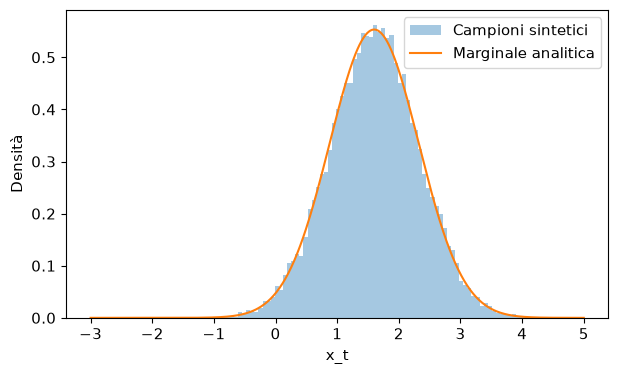

In [3]:
x0=2+.5*rng.standard_normal(20000); eps=rng.standard_normal(x0.size)
ab=.64; xt=np.sqrt(ab)*x0+np.sqrt(1-ab)*eps
scalar_xt=np.sqrt(ab)*2+np.sqrt(1-ab)*(-1)
reconstruction=(scalar_xt-np.sqrt(1-ab)*(-.9))/np.sqrt(ab)
diffusion={'media_teorica':2*np.sqrt(ab),'varianza_teorica':ab*.25+1-ab,
           'media_empirica_sintetica':xt.mean(),'varianza_empirica_sintetica':xt.var(),
           'xt_scalare':scalar_xt,'x0_stimato_scalare':reconstruction,
           'amplificazione_ab064':np.sqrt((1-ab)/ab),'amplificazione_ab004':np.sqrt(.96/.04)}
assert np.isclose(scalar_xt,1) and np.isclose(reconstruction,1.925)
print(diffusion); salva_json('diffusione.json',diffusion)
x=np.linspace(-3,5,500); mean=diffusion['media_teorica']; var=diffusion['varianza_teorica']
fig,ax=plt.subplots();ax.hist(xt,bins=80,density=True,alpha=.4,label='Campioni sintetici');ax.plot(x,np.exp(-(x-mean)**2/(2*var))/np.sqrt(2*np.pi*var),label='Marginale analitica');ax.set(xlabel='x_t',ylabel='Densità');ax.legend();fig.savefig(output/'marginale.png',dpi=180,bbox_inches='tight');plt.show()


### Interpretazione

N14.B.1 — Distinguere varianza condizionata 1−alpha cumulativo e varianza marginale osservata.

N14.B.2 — Spiegare il segno dell’errore di ricostruzione e perché aumenta ai livelli molto rumorosi.

## C — Guidance e campo di velocità

Le due previsioni CFG sono numeri assegnati. Il flow rettilineo da −1 a 2 usa una velocità costante esatta. La semplicità rende possibile un controllo dell’integratore.

In [4]:
scales=np.array([0.,1.,3.]); eps_u=.2; eps_c=.5
guided=eps_u+scales*(eps_c-eps_u)
def euler_constant(n):
    state=-1.; dt=1/n
    for _ in range(n): state+=dt*3
    return state
flow={'scale_CFG':scales,'previsioni_CFG':guided,'x_a_t025':-1+.25*3,
      'Euler_1_passo':euler_constant(1),'Euler_10_passi':euler_constant(10)}
assert np.allclose(guided,[.2,.5,1.1]) and np.isclose(euler_constant(1),2)
print(flow); salva_json('guidance_flow.json',flow)
np.savetxt(output/'guidance.csv',np.column_stack([scales,guided]),delimiter=',',header='scala,epsilon_combinata',comments='')


{'scale_CFG': array([0., 1., 3.]), 'previsioni_CFG': array([0.2, 0.5, 1.1]), 'x_a_t025': -0.25, 'Euler_1_passo': 2.0, 'Euler_10_passi': 2.0000000000000004}


### Interpretazione

N14.C.1 — Quali scale riproducono la previsione non condizionata e quella condizionata? Perché scala 3 è un’estrapolazione?

N14.C.2 — Perché l’esattezza di Eulero a un passo riguarda il campo assegnato e non tutti i generatori flow?

## Conservare e interpretare gli output

Controllare i file nella cartella di output e scaricarli insieme al notebook se si usa un runtime temporaneo. JSON e CSV distinguono valori analitici assegnati, campioni sintetici e risultati dei calcoli. Le verifiche numeriche non stimano le prestazioni dei modelli reali. Per studiarli occorrono pesi, dati, licenze e un protocollo separato.

## Risorse primarie e implementazioni ufficiali

- [CLIP, codice degli autori](https://github.com/openai/CLIP)

- [DDIM, codice degli autori](https://github.com/ermongroup/ddim)

- [Flow Matching, articolo](https://openreview.net/forum?id=PqvMRDCJT9t)